# Exercise 2 — Predict Miami house prices with TabPFN-3.5 Plus

Use TabPFN through **SAP AI Core**, then compare its predictions with a training-median baseline and XGBoost. The Miami housing dataset contains 13,776 property sales and 15 features describing location, size, age, and nearby amenities. You can switch to your own regression dataset in the configuration cell below.

TabPFN learns from labelled **context rows** supplied with each request; query rows contain only features. Held-out sale prices stay local for evaluation. This notebook requires a running SAP TabPFN-3.5 Plus deployment for prediction. See the [setup and data attribution](README.md) and [SAP API documentation](https://help.sap.com/docs/sap-ai-core/generative-ai/tabpfn-3-5-plus).


## 1. Set up

Install the exercise dependencies once, then restart the kernel if prompted. Launch this notebook from `exercises/ex2`. Copy `.env.example` to `.env` and fill in the SAP credentials and deployment ID from Exercise 0.


In [1]:
%pip install -q -r requirements.txt


Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from dotenv import load_dotenv

from helpers import (
    baseline_predictions,
    download_miami_housing,
    predict_sap_tabpfn,
    predict_sap_tabpfn_quantiles,
    predict_sap_tabpfn_full,
    plot_predictive_distribution,
    regression_metrics,
    select_context,
    split_regression_data,
)

load_dotenv(Path(".env"))


False

## 2. Choose your data and prediction target

`SALE_PRC` is the property sale price in US dollars. The supplied Miami dataset has already had the parcel identifier removed, so `DROP_COLUMNS` is empty. Use only information available when valuing a home; for a real deployment, check when each appraisal-derived feature was recorded.

The helper downloads [Miami housing from OpenML](https://www.openml.org/search?type=data&id=46942) on the first run and caches it as `miami_housing.csv`. See the README for attribution and the CC BY-NC-SA source license.

**Your own CSV:** change `CSV_PATH`, `TARGET_COLUMN`, and `DROP_COLUMNS`, then run the remaining cells. Set `SORT_COLUMN` for an ordered time split; leave it `None` for independent rows. Parse date strings explicitly below when using a time split. This exercise supports numeric regression targets; class labels need a classifier and classification metrics.


In [3]:
CSV_PATH = Path("miami_housing.csv")
TARGET_COLUMN = "SALE_PRC"
DROP_COLUMNS = []  # add identifiers or leaked outcomes for your own data
SORT_COLUMN = None  # e.g. "sale_date" for your own time-ordered data
TEST_SIZE = 0.2
MAX_CONTEXT_ROWS = 2_048  # workshop choice, not the model's maximum
RANDOM_STATE = 42

# For another dataset, for example:
# CSV_PATH = Path("my_data.csv")
# TARGET_COLUMN = "sales"
# DROP_COLUMNS = ["record_id", "revenue_after_sale"]

if CSV_PATH == Path("miami_housing.csv") and not CSV_PATH.exists():
    download_miami_housing(CSV_PATH)
df = pd.read_csv(CSV_PATH)
if SORT_COLUMN is not None:
    df[SORT_COLUMN] = pd.to_datetime(df[SORT_COLUMN], errors="raise")
print(f"{len(df):,} rows, {len(df.columns)} columns")
display(df.head())


13,776 rows, 16 columns


,LATITUDE,LONGITUDE,SALE_PRC,LND_SQFOOT,TOT_LVG_AREA,SPEC_FEAT_VAL,RAIL_DIST,OCEAN_DIST,WATER_DIST,CNTR_DIST,SUBCNTR_DI,HWY_DIST,age,avno60plus,month_sold,structure_quality
0,25.904986,-80.168793,235000.0,10016.0,1665.0,1036.0,2437.8,15352.9,2685.1,47229.0,43363.4,13492.3,65,0.0,3,2
1,25.906707,-80.180090,289900.0,8100.0,2785.0,10388.0,5628.4,19112.2,5121.7,47378.9,45171.4,9779.3,26,0.0,12,4
2,25.609195,-80.388475,265100.0,8925.0,1767.0,5820.0,4702.0,26217.1,12023.3,88603.0,37892.4,3361.5,19,0.0,9,2
3,25.733496,-80.283502,1325000.0,11000.0,2557.0,55020.0,6416.8,13343.0,1482.3,33691.3,9974.3,11428.8,1,0.0,12,5
4,25.714017,-80.296669,410000.0,11000.0,2112.0,0.0,3300.1,15585.0,5112.7,41051.6,10737.3,6938.4,61,0.0,10,4


## 3. Hold out evaluation rows and select context

The split happens before any baseline preprocessing. Missing targets cannot be used as labels; the helper reports and removes them. Non-numeric or infinite targets raise an error so you can fix them. Feature missing values are retained. For a time split, the test set is the newest rows and the context is the latest training rows. For repeated customers or other groups, replace this split with a group-aware split before drawing conclusions.


In [4]:
X_train, X_test, y_train, y_test = split_regression_data(
    df, target=TARGET_COLUMN, drop_columns=DROP_COLUMNS,
    test_size=TEST_SIZE, random_state=RANDOM_STATE, sort_column=SORT_COLUMN,
)
X_context, y_context = select_context(
    X_train, y_train, max_rows=MAX_CONTEXT_ROWS,
    random_state=RANDOM_STATE, chronological=SORT_COLUMN is not None,
)
print(f"Context: {len(X_context):,} | Test: {len(X_test):,} | Features: {X_context.shape[1]}")
display(X_context.head())


Context: 2,048 | Test: 2,756 | Features: 15


,LATITUDE,LONGITUDE,LND_SQFOOT,TOT_LVG_AREA,SPEC_FEAT_VAL,RAIL_DIST,OCEAN_DIST,WATER_DIST,CNTR_DIST,SUBCNTR_DI,HWY_DIST,age,avno60plus,month_sold,structure_quality
2932,25.698052,-80.395038,14546.0,4553.0,49350.0,13344.3,41784.4,29337.9,72402.1,27032.3,2901.1,0,0.0,10,4
3414,25.763986,-80.291616,6000.0,1231.0,580.0,5370.1,22009.7,5056.3,32850.6,11998.4,7261.3,16,0.0,2,4
10233,25.848563,-80.226789,4280.0,993.0,0.0,2751.9,35477.0,4649.3,28383.7,28383.7,6275.4,76,0.0,5,2
2341,25.932616,-80.291016,7500.0,1603.0,12135.0,16800.3,55956.3,793.4,65197.4,65197.4,2682.2,50,0.0,3,4
7790,25.817701,-80.209563,5000.0,1506.0,420.0,3018.4,25311.6,8021.9,15861.2,15861.2,1134.7,46,0.0,5,1


## 4. Establish baselines

All three methods see exactly the same context and test rows. The median predicts a single training-set value. XGBoost fits a fixed, untuned tree ensemble; its numeric imputation and categorical encoding are learned only from context rows. TabPFN receives the original feature values, without one-hot encoding.


In [5]:
predictions = baseline_predictions(
    X_context, y_context, X_test, random_state=RANDOM_STATE,
)
display(regression_metrics(y_test, predictions).round(2))


,MAE,MAPE (%),RMSE
Model,,,
Median,179385.23,41.68,339117.19
XGBoost,54706.70,12.27,125593.68


## 5. Predict with the SAP deployment

The helper authenticates with SAP AI Core, converts context and query data into the documented JSON format, sends requests in batches, and returns predictions in test-row order. Unlike RPT, the TabPFN `/predict` endpoint takes separate `x_train`, `y_train`, `x_test`, and `task_config` fields; its response uses `prediction`. No Prior Labs client token is needed here. This cell is the point at which context and test features are sent to your SAP deployment; use data suitable for that environment.


In [6]:
predictions["TabPFN-3.5 Plus"] = predict_sap_tabpfn(
    X_context, y_context, X_test, target_name=TARGET_COLUMN, random_state=RANDOM_STATE,
)


## 6. Compare and inspect errors

Lower is better for every metric: **MAE** is the average absolute error in target units; **RMSE** puts more weight on large misses; **MAPE (%)** is the average absolute percentage error. MAPE excludes zero-valued targets (and is undefined if all targets are zero); near-zero targets can still dominate it. For Miami housing, MAE and RMSE are in US dollars.


,MAE,MAPE (%),RMSE
Model,,,
Median,179385.23,41.68,339117.19
XGBoost,54706.70,12.27,125593.68
TabPFN-3.5 Plus,43279.78,9.76,96795.06


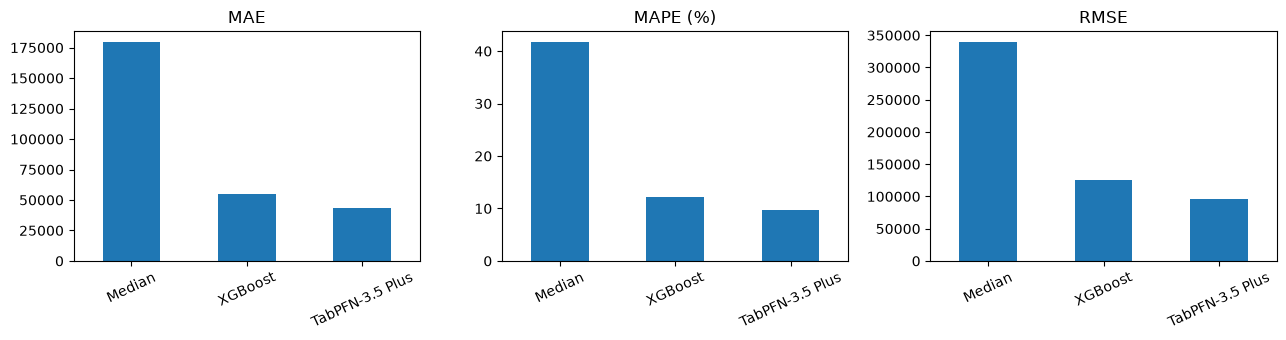

In [7]:
scores = regression_metrics(y_test, predictions)
display(scores.round(2))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for metric, ax in zip(scores.columns, axes):
    scores[metric].plot.bar(ax=ax, title=metric, rot=25)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()


In [8]:
results = X_test.copy()
results["Actual"] = y_test.to_numpy()
for name, values in predictions.items():
    results[f"Prediction: {name}"] = values
results["Absolute error: TabPFN"] = (
    results["Actual"] - results["Prediction: TabPFN-3.5 Plus"]
).abs()
display(results.sort_values("Absolute error: TabPFN", ascending=False).head(10))


,LATITUDE,LONGITUDE,LND_SQFOOT,TOT_LVG_AREA,SPEC_FEAT_VAL,RAIL_DIST,OCEAN_DIST,WATER_DIST,CNTR_DIST,SUBCNTR_DI,HWY_DIST,age,avno60plus,month_sold,structure_quality,Actual,Prediction: Median,Prediction: XGBoost,Prediction: TabPFN-3.5 Plus,Absolute error: TabPFN
10577,25.959519,-80.121505,13125.0,3482.0,42460.0,8385.9,865.5,18.8,59042.4,59042.4,14469.2,30,0.0,5,4,2600000.0,315000.0,1.102886e+06,1.453244e+06,1.146756e+06
9003,25.693414,-80.172028,9258.0,1710.0,5914.0,24092.1,311.5,294.5,30961.6,30961.6,23865.2,34,0.0,9,5,2300000.0,315000.0,1.068388e+06,1.284467e+06,1.015533e+06
9749,25.844334,-80.151635,9000.0,1924.0,0.0,12101.7,10709.9,11.0,27978.7,20649.0,12259.8,64,0.0,3,4,1650000.0,315000.0,6.721261e+05,6.777400e+05,9.722600e+05
12355,25.651752,-80.272579,12000.0,2638.0,3125.0,17964.7,1463.0,0.0,52396.6,18857.2,17162.9,27,0.0,3,4,1850000.0,315000.0,1.135585e+06,8.778541e+05,9.721459e+05
6752,25.816726,-80.187821,13760.0,3362.0,55598.0,525.9,21517.7,1065.7,14596.4,14596.4,1854.4,13,0.0,10,5,2500000.0,315000.0,1.015734e+06,1.585683e+06,9.143168e+05
518,25.674243,-80.283460,53579.0,4362.0,42052.0,9384.1,6621.0,1562.8,47575.5,10973.3,10377.3,26,0.0,6,4,2637500.0,315000.0,1.326342e+06,1.729258e+06,9.082415e+05
8982,25.866504,-80.130063,11250.0,2321.0,3158.0,15631.8,3538.9,13.2,38555.1,27500.1,19514.9,66,0.0,4,4,1850000.0,315000.0,8.576847e+05,9.631039e+05,8.868961e+05
10651,25.863171,-80.132900,11250.0,2213.0,10588.0,15267.7,4537.9,10.8,37004.3,26299.6,18233.2,47,0.0,6,5,2050000.0,315000.0,1.011807e+06,1.203278e+06,8.467222e+05
357,25.815968,-80.185134,13136.0,3067.0,41400.0,1443.5,20589.5,289.0,14419.7,14419.7,1565.2,21,0.0,1,5,2250000.0,315000.0,9.142819e+05,1.407307e+06,8.426928e+05
13018,25.814353,-80.186977,17605.0,3583.0,37087.0,987.4,21035.5,479.0,13736.3,13736.3,959.3,35,0.0,11,4,2000000.0,315000.0,8.526626e+05,1.234897e+06,7.651031e+05


## 7. Quantiles and the predictive distribution

A point estimate hides uncertainty. Request the 10th, 50th and 90th percentiles with `output_type="quantiles"`. The interval from the 10th to the 90th percentile is a **central 80% predictive interval**, not a confidence interval for the mean or a guarantee of coverage. We use the first 20 test homes to keep this extra request small.


,10%,50%,90%
11021,176855.187500,209752.656250,2.352086e+05
9608,397903.812500,451909.156250,5.100572e+05
7338,369223.093750,431710.812500,5.156626e+05
4097,211889.562500,232020.234375,2.476062e+05
7303,635447.187500,917971.125000,1.321024e+06
5284,151765.031250,175666.796875,1.941753e+05
12302,364588.187500,839536.812500,1.904722e+06
7567,183353.812500,202381.921875,2.186895e+05
12273,283916.000000,324140.187500,3.621519e+05
2357,159187.437500,214057.406250,2.476569e+05


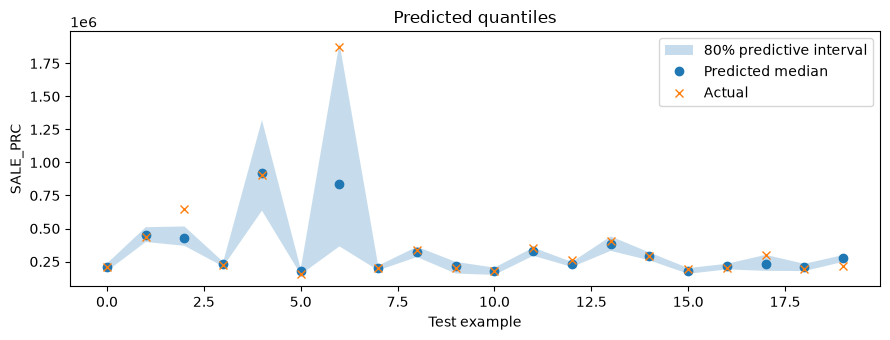

In [9]:
X_example = X_test.iloc[:20]
quantiles = predict_sap_tabpfn_quantiles(
    X_context, y_context, X_example, target_name=TARGET_COLUMN,
    quantiles=(0.1, 0.5, 0.9), random_state=RANDOM_STATE,
)
display(quantiles.rename(columns={0.1: "10%", 0.5: "50%", 0.9: "90%"}))

fig, ax = plt.subplots(figsize=(9, 3.5))
positions = range(len(X_example))
ax.fill_between(positions, quantiles[0.1], quantiles[0.9], alpha=0.25, label="80% predictive interval")
ax.plot(positions, quantiles[0.5], "o", label="Predicted median")
ax.plot(positions, y_test.loc[X_example.index], "x", label="Actual")
ax.set(xlabel="Test example", ylabel=TARGET_COLUMN, title="Predicted quantiles")
ax.legend()
plt.tight_layout()
plt.show()


Use `output_type="full"` to retrieve the distribution, rather than just selected quantiles. The helper below makes that request for **one home** and plots the returned probability mass in each bin. The outer bins include the distribution tails; bar heights are probabilities, not a continuous density. The horizontal axis zooms to the central 99% of predicted mass so extreme tail boundaries do not hide the distribution. The actual outcome is shown for comparison. Full-output requests are limited to 400 query rows by SAP.


Full-output fields: ['borders', 'logits', 'mean', 'median', 'mode', 'quantiles']


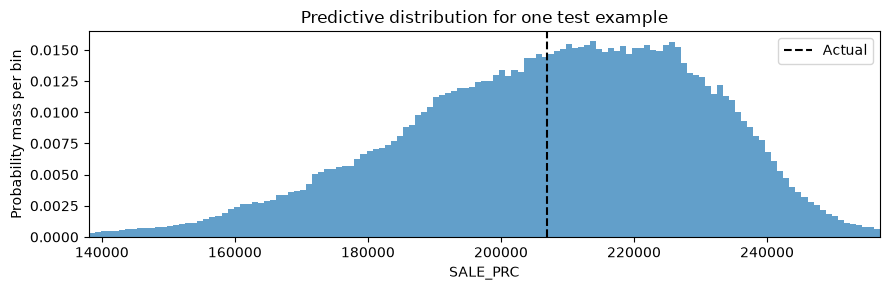

In [10]:
full_output = predict_sap_tabpfn_full(
    X_context, y_context, X_example.iloc[:1], target_name=TARGET_COLUMN,
    random_state=RANDOM_STATE,
)
print("Full-output fields:", sorted(full_output))
ax = plot_predictive_distribution(full_output, row=0)
ax.axvline(y_test.loc[X_example.index[0]], color="black", linestyle="--", label="Actual")
ax.set(xlabel=TARGET_COLUMN, title="Predictive distribution for one test example")
ax.legend()
plt.tight_layout()
plt.show()


## 8. Try your own data and iterate

Return to the configuration cell, point to your CSV, choose a numeric target and remove identifiers or leaked outcomes. Re-run from that cell to compare all three methods automatically. For a date-based split, choose the date that reflects when the prediction would actually be made.

- Does TabPFN beat both baselines on MAE and MAPE? Which metric matters for your use case?
- Which examples have the largest errors? Are their feature values unlike the context rows?
- Try more context rows, keeping the test split fixed and staying within your deployment's documented limits. All methods will use the new context.

Keep the test set for evaluation; use a separate validation split if you tune model settings repeatedly.


## 9. Optional: classify phishing websites

Now predict a **category** instead of a price. The website phishing dataset has 1,353 examples, nine features and three labels: **Legitimate**, **Phishy**, and **Suspicious**. We compare TabPFN with a majority-class baseline and XGBoost.

The data contains repeated feature patterns. Our repeatable split keeps identical feature vectors together, so they cannot appear in both training and test data. The test row fraction is approximate because groups differ in size.

Source: [OpenML 46963](https://www.openml.org/search?type=data&id=46963), derived from [UCI Website Phishing](https://doi.org/10.24432/C5B301), CC BY 4.0. See the README for attribution.

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay
from helpers import (
    download_website_phishing, split_classification_data, select_classification_context,
    classification_baseline_predictions, predict_sap_tabpfn_classification,
    classification_metrics,
)

CLASSIFICATION_CSV = Path("website_phishing.csv")
CLASSIFICATION_TARGET = "WebsiteType"
CLASSIFICATION_DROP_COLUMNS = []
CLASSIFICATION_CONTEXT_ROWS = 2048

if CLASSIFICATION_CSV == Path("website_phishing.csv") and not CLASSIFICATION_CSV.exists():
    download_website_phishing(CLASSIFICATION_CSV)
classification_df = pd.read_csv(CLASSIFICATION_CSV)
display(classification_df.head())
display(classification_df[CLASSIFICATION_TARGET].value_counts().rename("Examples"))

,SFH,popUpWidnow,SSLfinal_State,Request_URL,URL_of_Anchor,web_traffic,URL_Length,age_of_domain,having_IP_Address,WebsiteType
0,Legitimate,Legitimate,Phishy,Phishy,Legitimate,Phishy,Legitimate,Legitimate,Suspicious,Suspicious
1,Phishy,Phishy,Suspicious,Phishy,Phishy,Legitimate,Phishy,Phishy,Suspicious,Legitimate
2,Legitimate,Suspicious,Legitimate,Phishy,Legitimate,Phishy,Suspicious,Legitimate,Suspicious,Phishy
3,Legitimate,Suspicious,Legitimate,Legitimate,Legitimate,Phishy,Suspicious,Legitimate,Suspicious,Phishy
4,Phishy,Phishy,Legitimate,Phishy,Phishy,Suspicious,Suspicious,Legitimate,Suspicious,Legitimate


WebsiteType
Phishy        702
Legitimate    548
Suspicious    103
Name: Examples, dtype: int64

In [12]:
clf_X_train, clf_X_test, clf_y_train, clf_y_test = split_classification_data(
    classification_df, CLASSIFICATION_TARGET, drop_columns=CLASSIFICATION_DROP_COLUMNS,
    test_size=0.2, random_state=RANDOM_STATE, group_identical_features=True,
)
clf_X_context, clf_y_context = select_classification_context(
    clf_X_train, clf_y_train, max_rows=CLASSIFICATION_CONTEXT_ROWS, random_state=RANDOM_STATE,
)
print(f"Context: {len(clf_X_context):,} rows; test: {len(clf_X_test):,} rows")
display(pd.DataFrame({"Context": clf_y_context.value_counts(), "Test": clf_y_test.value_counts()}))

Context: 1,072 rows; test: 281 rows


,Context,Test
WebsiteType,,
Phishy,536,166
Legitimate,446,102
Suspicious,90,13


### Compare the three classifiers

The helper sends `task="classification"` and `output_type="preds"` to the same SAP deployment. All models use the same context and held-out examples. A median has no meaning for these labels, so the naive baseline predicts the most frequent context class.

In [13]:
clf_predictions = classification_baseline_predictions(
    clf_X_context, clf_y_context, clf_X_test, random_state=RANDOM_STATE,
)
clf_predictions["TabPFN-3.5 Plus"] = predict_sap_tabpfn_classification(
    clf_X_context, clf_y_context, clf_X_test,
    target_name=CLASSIFICATION_TARGET, random_state=RANDOM_STATE,
)
display(classification_metrics(clf_y_test, clf_predictions).round(3))

,Accuracy,Balanced accuracy,Macro F1
Model,,,
Majority class,0.591,0.333,0.248
XGBoost,0.915,0.918,0.833
TabPFN-3.5 Plus,0.929,0.948,0.901


Higher scores are better. **Accuracy** counts correct predictions. **Balanced accuracy** averages recall across classes, so the smaller Suspicious class matters equally. **Macro F1** averages each class's F1 score. The confusion matrix shows which categories TabPFN confuses.

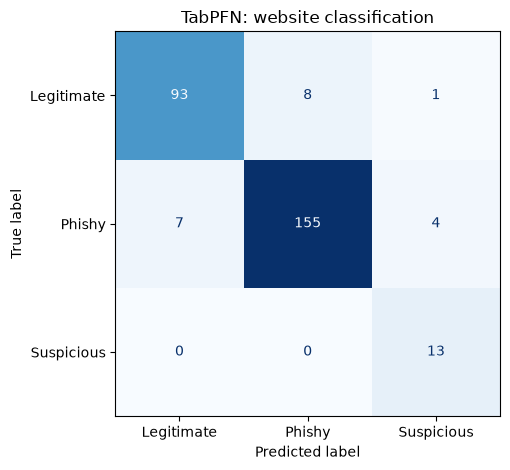

,Actual,Majority class,XGBoost,TabPFN-3.5 Plus
3,Phishy,Phishy,Phishy,Phishy
4,Legitimate,Phishy,Legitimate,Legitimate
5,Phishy,Phishy,Phishy,Phishy
6,Legitimate,Phishy,Legitimate,Legitimate
11,Phishy,Phishy,Suspicious,Suspicious
27,Legitimate,Phishy,Legitimate,Legitimate
43,Suspicious,Phishy,Suspicious,Suspicious
47,Legitimate,Phishy,Suspicious,Legitimate
50,Legitimate,Phishy,Legitimate,Legitimate
51,Phishy,Phishy,Phishy,Phishy


In [14]:
ConfusionMatrixDisplay.from_predictions(
    clf_y_test, clf_predictions["TabPFN-3.5 Plus"],
    labels=sorted(clf_y_context.unique()), cmap="Blues", colorbar=False,
)
plt.title("TabPFN: website classification")
plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "Actual": clf_y_test,
    **{name: values for name, values in clf_predictions.items()},
}).head(10))

### Try your own classification dataset

Change `CLASSIFICATION_CSV`, `CLASSIFICATION_TARGET`, and `CLASSIFICATION_DROP_COLUMNS`, then rerun this section. Use a categorical target with at least two classes and enough examples of every class for both splits. Drop identifiers and columns that reveal the answer. Missing targets are removed; feature preprocessing is handled by the helpers.

Keep identical-feature grouping enabled for repeated patterns. If rows repeat customers or other entities, use an entity-aware split; use a chronological split for future predictions. For independent rows, `group_identical_features=False` uses a stratified random split. You can change `CLASSIFICATION_CONTEXT_ROWS` to explore context size, but use a validation set when tuning.

Try inspecting misclassified Suspicious websites or dropping a feature. Which class is hardest to recognize?

Continue to [Exercise 3 — Tabular orchestration](../ex3/README.md).